# 01. Demand forecasting

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss  # test whether a time series is stationary
from statsmodels.stats.diagnostic import acorr_ljungbox  # test whether model residuals have significant autocorrelation
from statsmodels.stats.stattools import jarque_bera  # test whether residuals follow a normal distribution
from statsmodels.graphics.tsaplots import plot_acf  # plot autocorrelation to identify temporal patterns
from scipy.stats import shapiro  # test residuals for normality
from pmdarima import auto_arima  # automatically select ARIMA model parameters

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'

In [3]:
# get data
sales_long_agg = pd.read_csv(data_dir / 'sales_long_agg.csv')
sales_long_agg['date'] = pd.to_datetime(sales_long_agg['date'])

# check for consecutive dates
dr1 = pd.date_range(
    start=sales_long_agg['date'].min(),
    end=sales_long_agg['date'].max(),
    freq='D'
)
dr2 = sales_long_agg['date']
if len(dr1.symmetric_difference(dr2)) > 0:
    raise Exception('non consecutive')

# Outliers

In [4]:
# fix the outliers
p = sales_long_agg['units_sold'].describe(percentiles=np.arange(0,1.01,0.01))
p[:10]

count     1913.000000
mean     34341.562467
std       7345.905196
min         11.000000
0%          11.000000
1%       19584.840000
2%       21186.640000
3%       21849.400000
4%       22424.520000
5%       22779.200000
Name: units_sold, dtype: float64

In [5]:
p_0 = p.loc['0%']
p_1 = p.loc['1%']
print(p_0,p_1)

11.0 19584.84


In [6]:
sales_long_agg['units_sold'] = np.where(sales_long_agg['units_sold'] < p_1, p_1, sales_long_agg['units_sold'])

In [7]:
# check it
p = sales_long_agg['units_sold'].describe(percentiles=np.arange(0,1.01,0.01))
p[:10]

count     1913.000000
mean     34398.291061
std       7160.760827
min      19584.840000
0%       19584.840000
1%       19588.219200
2%       21186.640000
3%       21849.400000
4%       22424.520000
5%       22779.200000
Name: units_sold, dtype: float64

In [8]:
# prep
for_model = sales_long_agg.set_index('date').copy()

# Seasonal decomp
View these plots to understand trend and seasonality.
Annual drops in units sold are evident.  

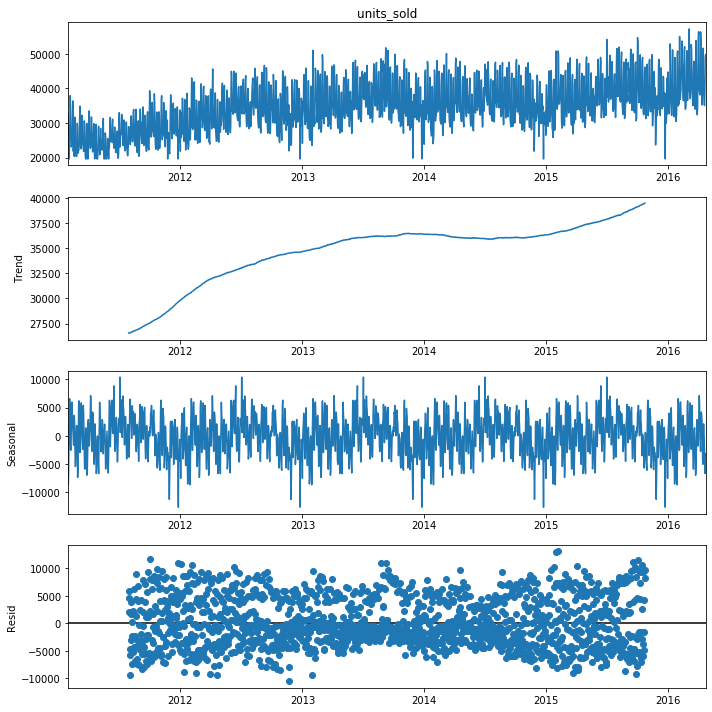

In [9]:
# view decomp
decomposition = seasonal_decompose(
    for_model['units_sold'],
    model='additive',
    period=365
)

fig = decomposition.plot()
fig.set_size_inches(10, 10)
plt.tight_layout()
plt.show()

# Seasonal-naive baseline
Create a simple baseline model against which we will judge all subsequent models

seasonal-naive mae: 3091.2
seasonal-naive wape: 8.98 %


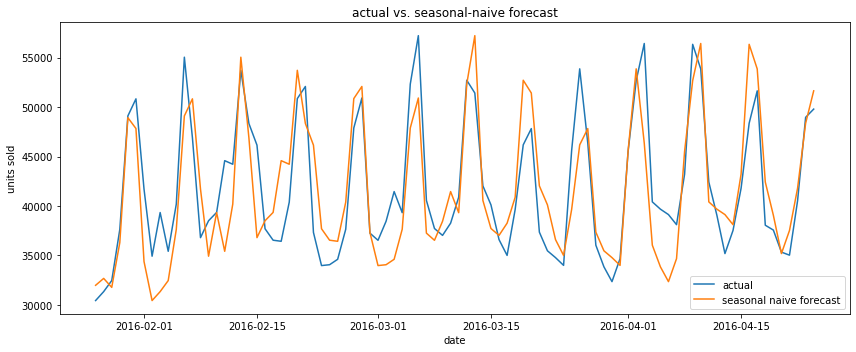

In [10]:
import warnings

warnings.filterwarnings(
    'ignore',
    category=FutureWarning,
    module='matplotlib'
)

# create naive forecast for baseline
# use last week's values to predict this week's values
for_model['naive_forecast'] = for_model['units_sold'].shift(7)

# evaluate where a forecast exists
evaluation = for_model.dropna(subset=['naive_forecast']).copy()

mae = np.mean(
    np.abs(evaluation['units_sold'] - evaluation['naive_forecast'])
)

wape = (
    np.abs(evaluation['units_sold'] - evaluation['naive_forecast']).sum()
    / evaluation['units_sold'].sum()
)

print('seasonal-naive mae:', round(mae, 2))
print('seasonal-naive wape:', round(wape * 100, 2), '%')

# compare actual sales with forecast
plt.figure(figsize=(12, 5))
plt.plot(
    evaluation.index[-90:],
    evaluation['units_sold'].iloc[-90:],
    label='actual'
)
plt.plot(
    evaluation.index[-90:],
    evaluation['naive_forecast'].iloc[-90:],
    label='seasonal naive forecast'
)
plt.title('actual vs. seasonal-naive forecast')
plt.xlabel('date')
plt.ylabel('units sold')
plt.legend()
plt.tight_layout()
plt.show()

# ARIMA

In [11]:
# prep time series
y = for_model['units_sold'].sort_index().astype(float)
y = y.asfreq('D')

# fill missing dates if any exist; assumes a straight line connects two points
y = y.interpolate(method='time')

# chronological train/test split
split_point = int(len(y) * 0.8)
train = y.iloc[:split_point]
test = y.iloc[split_point:]

print('observations:', len(y))
print('training:', len(train))
print('testing:', len(test))
y[:5]

observations: 1913
training: 1530
testing: 383


date
2011-01-29    32631.00
2011-01-30    31749.00
2011-01-31    23783.00
2011-02-01    25412.00
2011-02-02    19584.84
Freq: D, Name: units_sold, dtype: float64

## Inspect the series  
ARIMA uses patterns in past observations and past forecast errors to model a time series.  
We inspect autocorrelation to understand which patterns may need to be modeled.  
A repeating wave pattern in the ACF plot suggests seasonality of some sort.

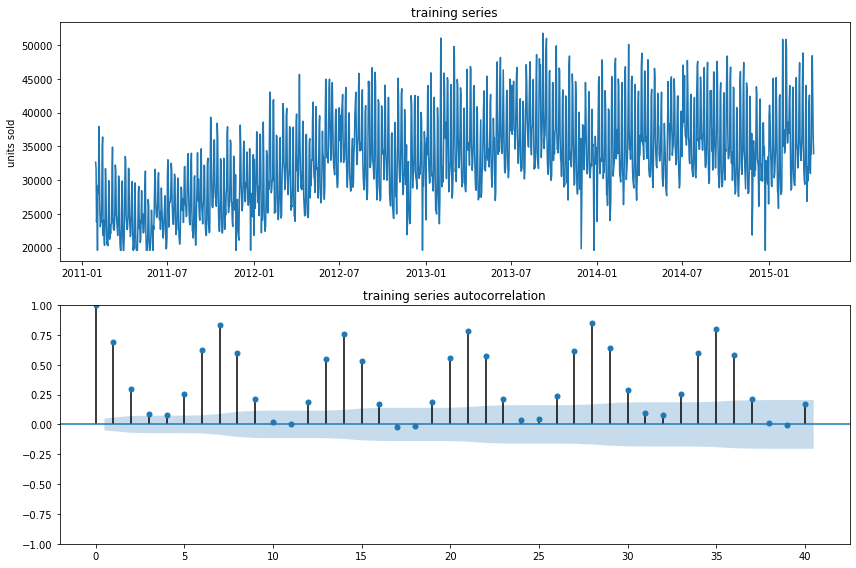

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(train.index, train.values)
axes[0].set_title('training series')
axes[0].set_ylabel('units sold')

plot_acf(train, lags=40, ax=axes[1])
axes[1].set_title('training series autocorrelation')

plt.tight_layout()
plt.show()

## Test raw-series stationarity
An assumption of the time series model is that the data be stationary.  
A stationary series has a relatively stable average, variability, and autocorrelation pattern over time.

ADF (Augmented Dickey-Fuller) tests whether a time series has a unit root, which is evidence of nonstationarity.  
The ADF null hypothesis is that the series has a unit root.  

KPSS tests the opposite hypothesis: its null hypothesis is that the series is stationary.

Below, we conclude the series is NOT stationary.

In [17]:
adf_result = adfuller(train.dropna())
print('\nADF statistic:', round(adf_result[0], 4))
print('ADF p-value:', round(adf_result[1], 4))

try:
    kpss_result = kpss(train.dropna(), regression='c', nlags='auto')
    print('KPSS statistic:', round(kpss_result[0], 4))
    print('KPSS p-value:', round(kpss_result[1], 4))
except Exception as e:
    print('KPSS test could not run:', e)

print('\nADF null hypothesis: series has a unit root.')
print('KPSS null hypothesis: series is stationary.')


ADF statistic: -2.0653
ADF p-value: 0.2587
KPSS statistic: 5.4896
KPSS p-value: 0.01

ADF null hypothesis: series has a unit root.
KPSS null hypothesis: series is stationary.


/opt/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/stattools.py:2019: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  warn_msg.format(direction="smaller"), InterpolationWarning


In [18]:
# start with the training series
stationary_series = train.astype(float).copy()

# apply first differencing to address trend or changing levels
stationary_series = stationary_series.diff().dropna()

# test stationarity
def test_stationarity(series, label):
    adf_p = adfuller(series)[1]
    kpss_p = kpss(series, regression='c', nlags='auto')[1]

    print(label)
    print('ADF p-value:', adf_p)
    print('KPSS p-value:', kpss_p)

    if adf_p < 0.05 and kpss_p >= 0.05:
        print('Result: evidence supports stationarity')
    else:
        print('Result: stationarity is not established')

    print()

test_stationarity(stationary_series, 'after first differencing')

after first differencing
ADF p-value: 5.493190900395811e-28
KPSS p-value: 0.1
Result: evidence supports stationarity



/opt/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/stattools.py:2023: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  warn_msg.format(direction="greater"), InterpolationWarning


## Fit auto arima
Uses ADF to help select differencing.  
Uses AIC to choose the best model, where AIC = Akaike Information Criterion, a score used to compare models and balance how well they fit the data against how complex they are (the lower, the better).

In [19]:
model = auto_arima(
    train,
    seasonal=True,
    m=7,
    d=None,
    D=1,
    stepwise=True,
    suppress_warnings=True,
    error_action='ignore',
    trace=True,
    max_p=3,
    max_q=3
)

print('\nselected model:')
print(model.summary())

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[7] intercept   : AIC=inf, Time=4.65 sec
 ARIMA(0,0,0)(0,1,0)[7] intercept   : AIC=29523.122, Time=0.06 sec
 ARIMA(1,0,0)(1,1,0)[7] intercept   : AIC=28856.082, Time=0.51 sec
 ARIMA(0,0,1)(0,1,1)[7] intercept   : AIC=28625.739, Time=2.05 sec
 ARIMA(0,0,0)(0,1,0)[7]             : AIC=29521.432, Time=0.04 sec
 ARIMA(0,0,1)(0,1,0)[7] intercept   : AIC=29250.636, Time=0.15 sec
 ARIMA(0,0,1)(1,1,1)[7] intercept   : AIC=28607.693, Time=2.17 sec
 ARIMA(0,0,1)(1,1,0)[7] intercept   : AIC=29063.877, Time=0.31 sec
 ARIMA(0,0,1)(2,1,1)[7] intercept   : AIC=28617.347, Time=3.88 sec
 ARIMA(0,0,1)(1,1,2)[7] intercept   : AIC=28654.828, Time=5.66 sec
 ARIMA(0,0,1)(0,1,2)[7] intercept   : AIC=28601.369, Time=7.71 sec
 ARIMA(0,0,0)(0,1,2)[7] intercept   : AIC=28963.370, Time=6.56 sec
 ARIMA(1,0,1)(0,1,2)[7] intercept   : AIC=inf, Time=8.06 sec
 ARIMA(0,0,2)(0,1,2)[7] intercept   : AIC=28528.471, Time=6.39 sec
 ARIMA(0,0,2)(0,1,1)[7] interce

## Forecast the held-out test period

In [20]:
forecast = model.predict(n_periods=len(test))
forecast = np.asarray(forecast)

actual = test.values
errors = actual - forecast

mae = np.mean(np.abs(errors))  # average absolute forecast error
rmse = np.sqrt(np.mean(errors ** 2))  # penalizes larger errors more heavily
wape = np.sum(np.abs(errors)) / np.sum(np.abs(actual))  # total absolute error as a proportion of actual sales

print('\ntest performance')
print('MAE:', round(mae, 2))
print('RMSE:', round(rmse, 2))
print('WAPE:', round(wape * 100, 2), '%')


test performance
MAE: 2744.79
RMSE: 3711.61
WAPE: 6.98 %


## Examine model residuals
Four main assumptions:
1. Zero mean  
2. Constant variance (homoscedasticity)  
3. No autocorrelation  
4. Normality  

mean residual: 138.26575044052674


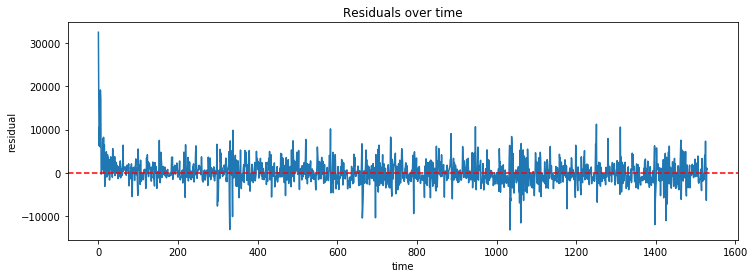

first-half variance: 9058373.921768764
second-half variance: 7471918.737107361


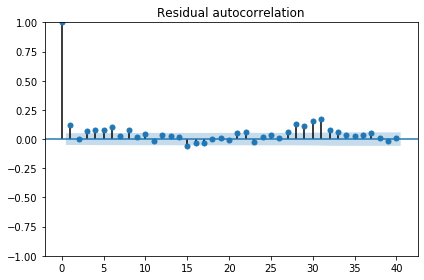

acorr_ljungbox results
      lb_stat     lb_pvalue
10  80.372067  4.244244e-13
20  91.715979  3.709282e-11
lag 10: reject null hypothesis - evidence of autocorrelation
lag 20: reject null hypothesis - evidence of autocorrelation


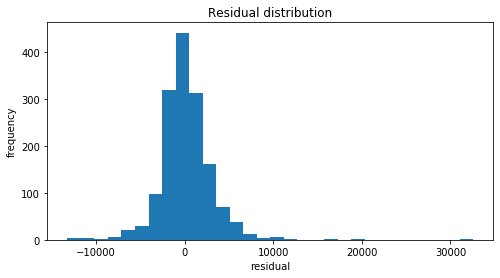

shapiro-wilk statistic: 0.9027531147003174
shapiro-wilk p-value: 4.034378238349812e-30
reject null hypothesis - evidence residuals are not normally distributed


In [21]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import numpy as np

# get in-sample residuals from the fitted model
residuals = np.asarray(model.resid())

# 1. zero mean
print('mean residual:', np.mean(residuals))

# 2. constant variance
plt.figure(figsize=(12, 4))
plt.plot(residuals)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals over time')
plt.xlabel('time')
plt.ylabel('residual')
plt.show()

# compare variance across the first and second halves
midpoint = len(residuals) // 2
print('first-half variance:', np.var(residuals[:midpoint]))
print('second-half variance:', np.var(residuals[midpoint:]))

# 3. no autocorrelation
plot_acf(residuals, lags=40)
plt.title('Residual autocorrelation')
plt.tight_layout()
plt.show()
# null hypothesis: residuals have no autocorrelation
print('acorr_ljungbox results')
ljung_box = acorr_ljungbox(residuals, lags=[10, 20], return_df=True)
print(ljung_box)

for lag, p_value in zip(ljung_box.index, ljung_box['lb_pvalue']):
    if p_value < 0.05:
        print('lag {}: reject null hypothesis - evidence of autocorrelation'.format(lag))
    else:
        print('lag {}: fail to reject null hypothesis - no significant autocorrelation detected'.format(lag))

# 4. normality
plt.figure(figsize=(8, 4))
plt.hist(residuals, bins=30)
plt.title('Residual distribution')
plt.xlabel('residual')
plt.ylabel('frequency')
plt.show()

# null hypothesis: residuals follow a normal distribution
shapiro_stat, shapiro_p = shapiro(residuals)
print('shapiro-wilk statistic:', shapiro_stat)
print('shapiro-wilk p-value:', shapiro_p)

if shapiro_p < 0.05:
    print('reject null hypothesis - evidence residuals are not normally distributed')
else:
    print('fail to reject null hypothesis - no significant evidence against normality')

The residuals need some work if we are to trust an ARIMA model.

## Plot actual vs forecast

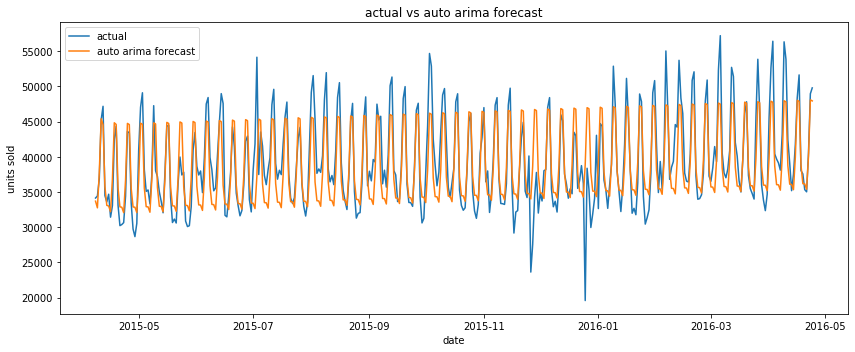

In [22]:
plt.figure(figsize=(12, 5))
plt.plot(test.index, actual, label='actual')
plt.plot(test.index, forecast, label='auto arima forecast')
plt.title('actual vs auto arima forecast')
plt.xlabel('date')
plt.ylabel('units sold')
plt.legend()
plt.tight_layout()
plt.show()

# Machine Learning
ARIMA beats seasonal-naive but it's not flexible enough to catch every signal.  
Instead, we will create features/columns and use a machine learning model. 

## Feature engineering

In [27]:
# get raw data
sales_long = (
    pd.read_csv(data_dir / "sales_long.csv", parse_dates=['date'])
)

print(sales_long.shape)

/opt/anaconda3/lib/python3.7/site-packages/IPython/core/interactiveshell.py:3326: DtypeWarning: Columns (14,15) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


(58327370, 17)


In [29]:
print(np.min(sorted(sales_long['date'].unique())))
print(np.max(sorted(sales_long['date'].unique())))

2011-01-29T00:00:00.000000000
2016-04-24T00:00:00.000000000


In [ ]:
# convert date and sort observations by item, store, and date
sales_long['date'] = pd.to_datetime(sales_long['date'])

sales_long = sales_long.sort_values(
    ['item_id', 'store_id', 'date']
).reset_index(drop=True).copy()

# calendar features
sales_long['day_of_week'] = sales_long['date'].dt.dayofweek
sales_long['day_of_month'] = sales_long['date'].dt.day
sales_long['week_of_year'] = sales_long['date'].dt.isocalendar().week.astype(int)
sales_long['month'] = sales_long['date'].dt.month
sales_long['year'] = sales_long['date'].dt.year
sales_long['is_weekend'] = (sales_long['day_of_week'] >= 5).astype(int)

# lag features: historical sales for the same item and store
lag_cols = []

grouped_sales_long = sales_long.groupby(['item_id', 'store_id'])['units_sold']

for lag in [1, 7, 14, 28]:
    col = 'lag_' + str(lag)
    sales_long[col] = grouped_sales_long.shift(lag)
    lag_cols.append(col)

# rolling statistics using only prior observations
rolling_cols = []

for window in [7, 28, 56]:
    mean_col = 'rolling_mean_' + str(window)
    std_col = 'rolling_std_' + str(window)

    sales_long[mean_col] = (
        sales_long.groupby(['item_id', 'store_id'])['units_sold']
        .transform(lambda x: x.shift(1).rolling(window).mean())
    )

    sales_long[std_col] = (
        sales_long.groupby(['item_id', 'store_id'])['units_sold']
        .transform(lambda x: x.shift(1).rolling(window).std())
    )

    rolling_cols.extend([mean_col, std_col])

# flag missing lag and rolling features
feature_cols_to_fill = lag_cols + rolling_cols

for col in feature_cols_to_fill:
    sales_long[col + '_missing'] = sales_long[col].isna().astype(int)

# fill missing lag and rolling features with zero
sales_long[feature_cols_to_fill] = (
    sales_long[feature_cols_to_fill].fillna(0)
)

In [ ]:
# define features and target
feature_cols = [
    'item_id',
    'store_id',
    'dept_id',
    'cat_id',
    'state_id',
    'day_of_week',
    'day_of_month',
    'week_of_year',
    'month',
    'year',
    'is_weekend',
    'lag_1',
    'lag_7',
    'lag_14',
    'lag_28',
    'rolling_mean_7',
    'rolling_mean_28',
    'rolling_mean_56',
    'rolling_std_7',
    'rolling_std_28',
    'rolling_std_56'
]

target_col = 'units_sold'

In [ ]:
# split into train and test sets
# use 28 days to capture roughly 4 weeks of activity
test_days = 28

dates = sorted(sales_long['date'].unique())
test_start = dates[-test_days]

train = sales_long[sales_long['date'] < test_start].copy()
test = sales_long[sales_long['date'] >= test_start].copy()

X_train = train[feature_cols].copy()
y_train = train[target_col]

X_test = test[feature_cols].copy()
y_test = test[target_col]

print('Training rows:', len(train))
print('Testing rows:', len(test))
print('Training dates:', train['date'].min().date(), 'to', train['date'].max().date())
print('Testing dates:', test['date'].min().date(), 'to', test['date'].max().date())

In [ ]:
# encode categorical variables
categorical_cols = [
    'item_id',
    'store_id',
    'dept_id',
    'cat_id',
    'state_id'
]

for col in categorical_cols:
    X_train[col] = X_train[col].astype('category')
    X_test[col] = X_test[col].astype('category')

# LightGBM
LightGBM can learn complex relationships between features that a traditional time-series model like ARIMA may not capture well.

In [ ]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

lgbm_model = LGBMRegressor(
    objective='regression',
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgbm_model.fit(
    X_train,
    y_train,
    categorical_feature=categorical_cols
)

lgbm_predictions = lgbm_model.predict(X_test)

mae = mean_absolute_error(y_test, lgbm_predictions)
rmse = np.sqrt(mean_squared_error(y_test, lgbm_predictions))
wape = np.abs(y_test - lgbm_predictions).sum() / y_test.sum()

print(f'MAE:  {mae:.4f}')
print(f'RMSE: {rmse:.4f}')
print(f'WAPE: {wape:.2%}')

In [ ]:
# inspect feature importance
importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': lgbm_model.feature_importances_
}).sort_values('importance', ascending=False)

importance.head(20)

In [ ]:
# aggregate actual sales and predictions by date
plot_data = pd.DataFrame({
    'date': test['date'].to_numpy(),
    'actual': y_test.to_numpy(),
    'predicted': lgbm_predictions
})

daily_results = (
    plot_data.groupby('date')[['actual', 'predicted']]
    .sum()
)

# plot actual sales against lightgbm predictions
plt.figure(figsize=(14, 6))
plt.plot(daily_results.index, daily_results['actual'], label='Actual', linewidth=2)
plt.plot(daily_results.index, daily_results['predicted'], label='LightGBM', linewidth=2)

plt.title('LightGBM: Actual vs. Predicted Daily Sales')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()